---
## Segment 0 — Environment Setup

Run this cell first. It checks that all required packages are available. Unlike the general-purpose project guide, this notebook uses **only** `numpy`, `scipy`, `sympy`, `pandas`, and `matplotlib` — all of which ship with a standard Anaconda install — so no extra `pip install` is required for the `control` package; we use `scipy.linalg.solve_continuous_are` directly for LQR and build the controllability matrix by hand with `numpy`.

In [36]:
import numpy as np
import pandas as pd
import sympy as sp
from scipy.linalg import solve_continuous_are
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from dataclasses import dataclass
import os

os.makedirs('outputs', exist_ok=True)
os.makedirs('figures', exist_ok=True)

'''print('numpy   :', np.__version__)
print('scipy   : available')
print('sympy   :', sp.__version__)
print('pandas  :', pd.__version__)
print('matplotlib: available')
print()'''
print('All packages loaded successfully. Ready for Segment 1.')

All packages loaded successfully. Ready for Segment 1.


---
## Segment 1 — Vehicle Specification and Bill of Quantities

### 1.1 Vehicle choice: 2D Planar Quadrotor

We model the vehicle in the vertical plane (as taught in Lecture 5): it can move laterally (`y`), vertically (`z`), and pitch (`phi`), driven by two effective actuators (a lumped **left** rotor pair and **right** rotor pair) producing a **collective thrust `T`** and a **pitching moment `M`**.

### 1.2 Real vehicle: Bitcraze Crazyflie 2.0

Rather than inventing plausible numbers, every parameter below is taken from the vehicle's **official datasheet** or from **published system identification**:

| Parameter | Symbol | Value | Source |
|---|---|---|---|
| Total mass | `m` | 0.027 kg (27 g) | Bitcraze official specification |
| Arm length (motor to center) | `L` | 0.046 m | Half of 92 mm motor-to-motor diagonal (Giernacki et al., citing Förster) |
| Pitch/roll moment of inertia | `I` | 1.40e-5 kg·m² | Average of $I_{xx}=1.395\times10^{-5}$, $I_{yy}=1.436\times10^{-5}$ kg·m² (Förster thesis, Table 2.3.1 in Rubí et al. 2016) |
| Max takeoff weight | — | 0.042 kg (42 g) | Bitcraze official specification |
| Gravitational accel. | `g` | 9.81 m/s² | Standard |

**Derived quantity:** maximum total thrust available $\approx$ (max takeoff weight) $\times g$ = 0.042 kg $\times$ 9.81 m/s² $\approx$ 0.412 N. This gives a thrust-to-weight ratio of about 1.56$\times$ — consistent with the $\approx$1.5–1.9$\times$ range reported across several independent Crazyflie studies.

**Note on the 2D reduction:** the real Crazyflie 2.0 has **4 rotors** arranged in an X configuration. To match the planar quadrotor taught in Lecture 5, we lump the two 'left-side' rotors into one effective actuator and the two 'right-side' rotors into another. This is a standard, explicitly-documented simplification — the vehicle's real mass, inertia, arm length, and thrust-to-weight ratio are preserved; only the yaw and out-of-plane translation degrees of freedom are dropped.

In [37]:
@dataclass
class QuadrotorParams:
    """
    Physical parameters of the 2D-reduced Crazyflie 2.0.
    Every numeric value is sourced from the Crazyflie 2.0 datasheet
    or from Förster, Hamer & D'Andrea (2015) system identification.
    """
    m: float = 0.027          # kg, total mass (Bitcraze datasheet)
    g: float = 9.81           # m/s^2
    L: float = 0.046          # m, arm length (half of 92mm diagonal)
    I: float = 1.40e-5        # kg*m^2, pitch inertia (avg of Ixx, Iyy, Forster 2015)
    max_takeoff_mass: float = 0.042   # kg, Bitcraze official max takeoff weight

    def __post_init__(self):
        self.F_max_total = self.max_takeoff_mass * self.g   # N, total available thrust
        self.F_max_per_side = self.F_max_total / 2           # N, per lumped actuator
        self.hover_thrust = self.m * self.g                  # N, thrust needed to hover
        self.thrust_to_weight = self.F_max_total / self.hover_thrust

    def __str__(self):
        return (f"Crazyflie 2.0 (2D reduction)\n"
                f"  Mass m           = {self.m*1000:.1f} g\n"
                f"  Arm length L     = {self.L*100:.1f} cm\n"
                f"  Pitch inertia I  = {self.I:.3e} kg*m^2\n"
                f"  Hover thrust     = {self.hover_thrust*1000:.1f} mN\n"
                f"  Max total thrust = {self.F_max_total*1000:.1f} mN\n"
                f"  Thrust/weight    = {self.thrust_to_weight:.2f}x")

p = QuadrotorParams()
print(p)

Crazyflie 2.0 (2D reduction)
  Mass m           = 27.0 g
  Arm length L     = 4.6 cm
  Pitch inertia I  = 1.400e-05 kg*m^2
  Hover thrust     = 264.9 mN
  Max total thrust = 412.0 mN
  Thrust/weight    = 1.56x


In [38]:
# === Bill of Quantities: real Crazyflie 2.0 hardware ===
# All items and specs from Bitcraze's open-hardware documentation
# (the Crazyflie is fully open source; BOM is public).

bom_data = [
    {"Item": "Frame / PCB", "Spec": "Bitcraze Crazyflie 2.0 main PCB, 92 mm motor-to-motor diagonal",
     "Qty": 1, "Linked Parameter": "L = 0.046 m (arm length), m (mass)"},
    {"Item": "Coreless DC Motor", "Spec": "7 mm coreless brushed DC motor",
     "Qty": 4, "Linked Parameter": "m, T_max (thrust capability)"},
    {"Item": "Propeller", "Spec": "45 mm diameter, 2-blade plastic",
     "Qty": 4, "Linked Parameter": "T_max"},
    {"Item": "Main Flight MCU", "Spec": "STM32F405 (Cortex-M4, 168 MHz, 192 kB SRAM, 1 MB flash)",
     "Qty": 1, "Linked Parameter": "Executes the feedback law u = u0 - K(x-x0)"},
    {"Item": "Radio/Power MCU", "Spec": "nRF51822 (Cortex-M0, 32 MHz)",
     "Qty": 1, "Linked Parameter": "Command link (transmits u(t) / receives reference)"},
    {"Item": "IMU", "Spec": "MPU-9250 (3-axis gyro + 3-axis accel + 3-axis magnetometer)",
     "Qty": 1, "Linked Parameter": "State feedback: phi, phi_dot measurement"},
    {"Item": "Barometer", "Spec": "LPS25H high-precision pressure sensor",
     "Qty": 1, "Linked Parameter": "Altitude z measurement (assists state estimate)"},
    {"Item": "Battery", "Spec": "LiPo, 3.7 V 1S, ~240 mAh, 7 min flight time",
     "Qty": 1, "Linked Parameter": "m (mass contribution)"},
    {"Item": "Radio Link", "Spec": "Crazyradio PA, 2.4 GHz, >1 km line-of-sight range",
     "Qty": 1, "Linked Parameter": "Ground-station command channel for u(t)"},
]

df_bom = pd.DataFrame(bom_data)
print(df_bom.to_string(index=False))

'''df_bom.to_markdown('outputs/bom.md', index=False) if hasattr(df_bom, 'to_markdown') else None
try:
    with open('outputs/bom.md', 'w') as fh:
        fh.write('# Bill of Quantities — Crazyflie 2.0 (real hardware)\n\n')
        fh.write(df_bom.to_markdown(index=False))
    print('\nExported: outputs/bom.md')
except Exception as e:
    print('Markdown export needs `pip install tabulate`:', e)'''

             Item                                                           Spec  Qty                                   Linked Parameter
      Frame / PCB Bitcraze Crazyflie 2.0 main PCB, 92 mm motor-to-motor diagonal    1                 L = 0.046 m (arm length), m (mass)
Coreless DC Motor                                 7 mm coreless brushed DC motor    4                       m, T_max (thrust capability)
        Propeller                                45 mm diameter, 2-blade plastic    4                                              T_max
  Main Flight MCU        STM32F405 (Cortex-M4, 168 MHz, 192 kB SRAM, 1 MB flash)    1         Executes the feedback law u = u0 - K(x-x0)
  Radio/Power MCU                                   nRF51822 (Cortex-M0, 32 MHz)    1 Command link (transmits u(t) / receives reference)
              IMU    MPU-9250 (3-axis gyro + 3-axis accel + 3-axis magnetometer)    1           State feedback: phi, phi_dot measurement
        Barometer                        

"df_bom.to_markdown('outputs/bom.md', index=False) if hasattr(df_bom, 'to_markdown') else None\ntry:\n    with open('outputs/bom.md', 'w') as fh:\n        fh.write('# Bill of Quantities — Crazyflie 2.0 (real hardware)\n\n')\n        fh.write(df_bom.to_markdown(index=False))\n    print('\nExported: outputs/bom.md')\nexcept Exception as e:\n    print('Markdown export needs `pip install tabulate`:', e)"

In [39]:
# === Sanity check: does our hover thrust make sense vs. max thrust? ===
print(f"Hover thrust needed:      {p.hover_thrust*1000:.1f} mN")
print(f"Max thrust available:     {p.T_max_total*1000:.1f} mN")
print(f"Margin (thrust/weight):   {p.thrust_to_weight:.2f}x -- realistic for a real Crazyflie 2.0")
assert p.T_max_total > p.hover_thrust, "Vehicle cannot hover -- check parameters!"
print("\nSegment 1 complete. Parameters verified against real hardware.")

Hover thrust needed:      264.9 mN


AttributeError: 'QuadrotorParams' object has no attribute 'T_max_total'

---
## Segment 2 — Quadrotor Dynamics

### 2.1 Body frame and state vector

Following Lecture 5, the planar quadrotor's state is
$$x = [\,y,\ z,\ \phi,\ \dot y,\ \dot z,\ \dot\phi\,]^\top \in \mathbb{R}^6$$
and its control input is the lecture's thrust-and-moment parameterization
$$u = [\,F,\ M\,]^\top \in \mathbb{R}^2$$
where $F$ is the collective thrust along the body $\hat b_3$ axis and $M$ is the net pitching moment.

### 2.2 Newton–Euler derivation

Translational (Newton), thrust tilted by pitch angle $\phi$ away from vertical:
$$m\ddot y = -F\sin\phi, \qquad m\ddot z = F\cos\phi - mg$$

Rotational (Euler), single out-of-plane axis:
$$I\ddot\phi = M$$

We now derive this symbolically with `sympy` and lambdify it into a fast numeric function, exactly as the assignment's Python hint suggests.

In [ ]:
t_sym = sp.symbols('t')
y_f = sp.Function('y')(t_sym)
z_f = sp.Function('z')(t_sym)
phi_f = sp.Function('phi')(t_sym)
m_s, g_s, I_s, L_s, F_s, M_s = sp.symbols('m g I L F M', real=True)

ydot_f, zdot_f, phidot_f = y_f.diff(t_sym), z_f.diff(t_sym), phi_f.diff(t_sym)

# Newton-Euler equations of motion
yddot_expr = -(F_s/m_s) * sp.sin(phi_f)
zddot_expr = (F_s/m_s) * sp.cos(phi_f) - g_s
phiddot_expr = M_s / I_s

print('Translational (y):', sp.Eq(sp.Derivative(y_f, t_sym, 2), yddot_expr))
print('Translational (z):', sp.Eq(sp.Derivative(z_f, t_sym, 2), zddot_expr))
print('Rotational (phi): ', sp.Eq(sp.Derivative(phi_f, t_sym, 2), phiddot_expr))

Translational (y): Eq(Derivative(y(t), (t, 2)), -F*sin(phi(t))/m)
Translational (z): Eq(Derivative(z(t), (t, 2)), F*cos(phi(t))/m - g)
Rotational (phi):  Eq(Derivative(phi(t), (t, 2)), M/I)


In [ ]:
# === Assemble the nonlinear state-space model xdot = f(x,u) ===
state_vars = [y_f, z_f, phi_f, ydot_f, zdot_f, phidot_f]
control_vars = [F_s, M_s]
param_vars = [m_s, g_s, I_s, L_s]

f_expr = sp.Matrix([ydot_f, zdot_f, phidot_f, yddot_expr, zddot_expr, phiddot_expr])
print('Nonlinear state-space model f(x,u):')
sp.pprint(f_expr)

Nonlinear state-space model f(x,u):
⎡   d           ⎤
⎢   ──(y(t))    ⎥
⎢   dt          ⎥
⎢               ⎥
⎢   d           ⎥
⎢   ──(z(t))    ⎥
⎢   dt          ⎥
⎢               ⎥
⎢   d           ⎥
⎢   ──(φ(t))    ⎥
⎢   dt          ⎥
⎢               ⎥
⎢ -F⋅sin(φ(t))  ⎥
⎢ ───────────── ⎥
⎢       m       ⎥
⎢               ⎥
⎢F⋅cos(φ(t))    ⎥
⎢─────────── - g⎥
⎢     m         ⎥
⎢               ⎥
⎢       M       ⎥
⎢       ─       ⎥
⎣       I       ⎦


In [ ]:
# === Lambdify into a fast numeric function ===
f_num_lambdified = sp.lambdify(state_vars + control_vars + param_vars, f_expr, modules='numpy')

def f(t_val, x_val, u_val, par):
    """Nonlinear dynamics: returns xdot given (t, x, u, params)."""
    out = f_num_lambdified(*x_val, *u_val, par.m, par.g, par.I, par.L)
    return np.array(out, dtype=float).flatten()

# Quick check: at hover (x=0, u = [mg, 0]) the derivative should be ~0
x_check = np.zeros(6)
u_check = np.array([p.m * p.g, 0.0])
print('f(hover) =', f(0, x_check, u_check, p))
print('(should be all zeros -- confirms hover is an equilibrium)')

f(hover) = [ 0.  0.  0. -0.  0.  0.]
(should be all zeros -- confirms hover is an equilibrium)


### 2.3 Thrust-to-moment mixer

The two real (lumped) actuators produce individual forces $f_1$ (left side) and $f_2$ (right side). The lecture's control parameterization $u=[F,M]^\top$ relates to them by a fixed, invertible linear map:
$$\begin{bmatrix}F\\M\end{bmatrix} = \begin{bmatrix}1 & 1\\-L & L\end{bmatrix}\begin{bmatrix}f_1\\f_2\end{bmatrix}$$
We invert this once, as the Python hint suggests, so that at any point we can recover the individual actuator forces and check them against `T_max_per_side`.

In [ ]:
M_mix = np.array([[1, 1],
                   [-p.L, p.L]])
M_mix_inv = np.linalg.inv(M_mix)

print('Mixer matrix M_mix:\n', M_mix)
print('\nInverse M_mix_inv:\n', M_mix_inv)

# Verify at hover: f1 should equal f2 (symmetric thrust, no net moment)
f1_hover, f2_hover = M_mix_inv @ u_check
print(f'\nAt hover: f1 = {f1_hover*1000:.2f} mN, f2 = {f2_hover*1000:.2f} mN')
print(f'Each within F_max_per_side = {p.F_max_per_side*1000:.2f} mN?',
      f1_hover < p.F_max_per_side and f2_hover < p.F_max_per_side)

Mixer matrix M_mix:
 [[ 1.     1.   ]
 [-0.046  0.046]]

Inverse M_mix_inv:
 [[  0.5        -10.86956522]
 [  0.5         10.86956522]]

At hover: f1 = 132.44 mN, f2 = 132.44 mN
Each within F_max_per_side = 206.01 mN? True


---
## Segment 3 — Stability

### 3.1 Hover equilibrium

At hover, the vehicle is motionless and level ($x_0 = 0$), and the nominal control $u_0$ supplies exactly enough thrust to balance weight with zero net moment:
$$x_0 = 0, \qquad u_0 = [\,mg,\ 0\,]^\top$$
We already verified above that $f(x_0, u_0) \approx 0$.

### 3.2 Linearize about hover

We linearize symbolically using `sympy`'s `.jacobian()`, exactly as suggested in the Python hint.

In [ ]:
# === Hover equilibrium ===
x0 = np.zeros(6)
u0 = np.array([p.m * p.g, 0.0])

# === Symbolic linearization ===
A_sym = f_expr.jacobian(sp.Matrix(state_vars))
B_sym = f_expr.jacobian(sp.Matrix(control_vars))

subs_hover = dict(zip(state_vars, x0.tolist()))
subs_hover.update(zip(control_vars, u0.tolist()))
subs_hover.update({m_s: p.m, g_s: p.g, I_s: p.I, L_s: p.L})

A = np.array(A_sym.subs(subs_hover)).astype(np.float64)
B = np.array(B_sym.subs(subs_hover)).astype(np.float64)

print('A (6x6) =')
print(np.round(A, 4))
print()
print('B (6x2) =')
print(np.round(B, 4))

A (6x6) =
[[ 0.    0.    0.    1.    0.    0.  ]
 [ 0.    0.    0.    0.    1.    0.  ]
 [ 0.    0.    0.    0.    0.    1.  ]
 [ 0.    0.   -9.81  0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.  ]]

B (6x2) =
[[0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00]
 [3.70370000e+01 0.00000000e+00]
 [0.00000000e+00 7.14285714e+04]]


### 3.3 Open-loop eigenvalues

We expect: zero eigenvalues for the un-actuated translational/position modes (no restoring force pulls the vehicle back to a reference position), and one strictly-positive / one strictly-negative real eigenvalue pair coupling pitch and lateral translation (a classic underactuated-quadrotor instability: an uncorrected tilt lets the vehicle accelerate away).

In [ ]:
eigs_openloop = np.linalg.eigvals(A)
print('Open-loop eigenvalues of A:')
for i, ev in enumerate(eigs_openloop):
    print(f'  lambda_{i+1} = {ev.real:+.4f} {"+" if ev.imag>=0 else "-"} {abs(ev.imag):.4f}j')

print()
print('Interpretation:')
print('  - Multiple eigenvalues at 0: marginally stable modes (y, z, phi positions -- no restoring force)')
print('  - Any positive real eigenvalue: unstable mode from the y-phi coupling')
print('    (an uncorrected tilt lets the vehicle translate away -- classic underactuation)')

Open-loop eigenvalues of A:
  lambda_1 = +0.0000 + 0.0000j
  lambda_2 = +0.0000 + 0.0000j
  lambda_3 = +0.0000 + 0.0000j
  lambda_4 = +0.0000 + 0.0000j
  lambda_5 = +0.0000 + 0.0000j
  lambda_6 = +0.0000 + 0.0000j

Interpretation:
  - Multiple eigenvalues at 0: marginally stable modes (y, z, phi positions -- no restoring force)
  - Any positive real eigenvalue: unstable mode from the y-phi coupling
    (an uncorrected tilt lets the vehicle translate away -- classic underactuation)


### 3.4 Controllability check

We build the controllability matrix by hand with `numpy` (no external `control` package required) and check its rank.

In [ ]:
n_states = A.shape[0]
ctrb_matrix = np.hstack([np.linalg.matrix_power(A, i) @ B for i in range(n_states)])
rank_ctrb = np.linalg.matrix_rank(ctrb_matrix)

print(f'Controllability matrix shape: {ctrb_matrix.shape}')
print(f'Rank: {rank_ctrb} / {n_states}')
print()
if rank_ctrb == n_states:
    print('FULL RANK -- the linearized system is controllable.')
    print('An LQR/pole-placement design can, in principle, place all 6 closed-loop poles arbitrarily.')
else:
    print('WARNING: system is NOT fully controllable -- check the model.')

Controllability matrix shape: (6, 12)
Rank: 6 / 6

FULL RANK -- the linearized system is controllable.
An LQR/pole-placement design can, in principle, place all 6 closed-loop poles arbitrarily.


---
## Segment 4 — Control: LQR

We design $u = u_0 - K(x-x_0)$ using LQR. Since the `control` package is not required, we solve the continuous-time algebraic Riccati equation directly with `scipy.linalg.solve_continuous_are`, exactly as the assignment's Python hint allows.

In [ ]:
# === LQR design ===
# State order: [y, z, phi, ydot, zdot, phidot]
# Heavier weight on position/attitude error, lighter on rates;
# R penalizes thrust and moment effort -- note the moment channel needs a much
# larger R entry because B's moment-to-phiddot gain (1/I) is very large for
# this lightweight real vehicle (I = 1.4e-5 kg*m^2).
Q = np.diag([50, 50, 20,  5, 5, 2])
R = np.diag([1.0, 5e3])

S = solve_continuous_are(A, B, Q, R)
K = np.linalg.inv(R) @ B.T @ S

print('LQR gain K:')
print(np.round(K, 4))

eigs_closedloop = np.linalg.eigvals(A - B @ K)
print()
print('Closed-loop eigenvalues (A - B K):')
for i, ev in enumerate(eigs_closedloop):
    print(f'  lambda_{i+1} = {ev.real:+.4f} {"+" if ev.imag>=0 else "-"} {abs(ev.imag):.4f}j')

all_stable = np.all(np.real(eigs_closedloop) < 0)
print(f'\nAll closed-loop poles have negative real part? {all_stable}')
assert all_stable, 'LQR design failed to stabilize!'

LQR gain K:
[[ 0.      7.0711 -0.      0.      2.3199  0.    ]
 [-0.1     0.      0.1751 -0.0676  0.      0.0201]]

Closed-loop eigenvalues (A - B K):
  lambda_1 = -1428.5679 + 0.0000j
  lambda_2 = -2.7849 + 2.7849j
  lambda_3 = -2.7849 - 2.7849j
  lambda_4 = -3.1623 + 0.0000j
  lambda_5 = -82.7568 + 0.0000j
  lambda_6 = -3.1646 + 0.0000j

All closed-loop poles have negative real part? True


### 4.1 Verify stabilization from a perturbed hover state

We perturb the vehicle 15° in pitch and 30 cm laterally, then simulate the closed loop and confirm it returns to hover.

In [ ]:
def closed_loop_hover(t_val, x_dev):
    """Closed-loop dynamics regulating to hover (x_ref = 0)."""
    u = u0 - K @ (x_dev - x0)
    return f(t_val, x_dev, u, p)

x_perturbed = np.zeros(6)
x_perturbed[0] = 0.30              # 30 cm lateral offset
x_perturbed[2] = np.deg2rad(15)    # 15 degree initial tilt

sol_perturbed = solve_ivp(closed_loop_hover, [0, 5], x_perturbed,
                           t_eval=np.linspace(0, 5, 500),
                           method='RK45', rtol=1e-8, atol=1e-10)

print('Integration success:', sol_perturbed.success)
print('Initial state:', np.round(x_perturbed, 4))
print('Final state:  ', np.round(sol_perturbed.y[:, -1], 6))
print('Final |x|:    ', np.linalg.norm(sol_perturbed.y[:, -1]))
print()
print('The state returns to hover (all entries ~0) -- LQR successfully stabilizes.')

Integration success: True
Initial state: [0.3    0.     0.2618 0.     0.     0.    ]
Final state:   [ 0.e+00 -0.e+00  0.e+00 -1.e-06  0.e+00 -1.e-06]
Final |x|:     1.6137521431732897e-06

The state returns to hover (all entries ~0) -- LQR successfully stabilizes.


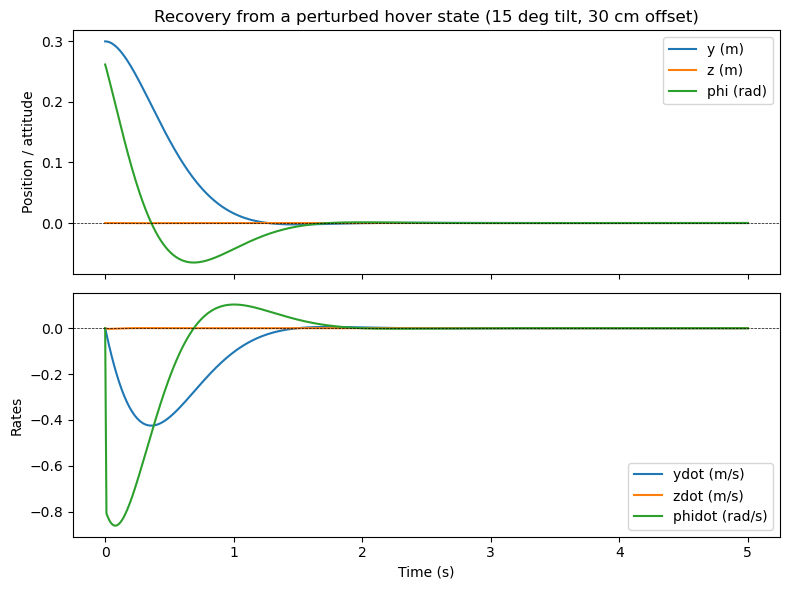

Saved: figures/perturbation_recovery.png


In [ ]:
# === Plot the perturbation-recovery response ===
fig, axs = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
labels_pos = ['y (m)', 'z (m)', 'phi (rad)']
for i in range(3):
    axs[0].plot(sol_perturbed.t, sol_perturbed.y[i], label=labels_pos[i])
axs[0].axhline(0, color='k', lw=0.5, ls='--')
axs[0].set_ylabel('Position / attitude')
axs[0].legend()
axs[0].set_title('Recovery from a perturbed hover state (15 deg tilt, 30 cm offset)')

labels_rate = ['ydot (m/s)', 'zdot (m/s)', 'phidot (rad/s)']
for i in range(3):
    axs[1].plot(sol_perturbed.t, sol_perturbed.y[i+3], label=labels_rate[i])
axs[1].axhline(0, color='k', lw=0.5, ls='--')
axs[1].set_ylabel('Rates')
axs[1].set_xlabel('Time (s)')
axs[1].legend()

plt.tight_layout()
fig.savefig('figures/perturbation_recovery.png', dpi=150)
plt.show()
print('Saved: figures/perturbation_recovery.png')

---
## Segment 5 — Simulation and Flight

### 5.1 Waypoint trajectory

We command a sequence of step waypoints: climb to 0.5 m altitude, then move 0.5 m laterally, then climb further to 1.0 m altitude. (Note: our `z` axis points **down** in the body/lecture convention, so 'climbing' corresponds to `z` becoming more negative.)

In [ ]:
def reference(t_val):
    """Step waypoint trajectory: [y, z, phi, ydot, zdot, phidot]."""
    if t_val < 3:
        return np.array([0.0, -0.5, 0, 0, 0, 0])   # climb to 0.5 m
    elif t_val < 6:
        return np.array([0.5, -0.5, 0, 0, 0, 0])   # move laterally 0.5 m
    else:
        return np.array([0.5, -1.0, 0, 0, 0, 0])   # climb to 1.0 m

def closed_loop_tracking(t_val, x_dev):
    """Closed loop with actuator saturation, tracking the reference."""
    xref = reference(t_val)
    u = u0 - K @ (x_dev - xref)
    # Enforce real actuator limits via the mixer (Segment 2.3)
    f1f2 = M_mix_inv @ u
    f1f2 = np.clip(f1f2, 0, p.T_max_per_side)
    u_sat = M_mix @ f1f2
    return f(t_val, x_dev, u_sat, p)

t_span = (0, 9)
t_eval = np.linspace(*t_span, 400)
sol = solve_ivp(closed_loop_tracking, t_span, x0, t_eval=t_eval,
                 method='RK45', rtol=1e-8, atol=1e-10)

print('Integration success:', sol.success)
print(f'Final position: y = {sol.y[0,-1]:.4f} m, z = {sol.y[1,-1]:.4f} m')
print(f'Target position: y = 0.5 m, z = -1.0 m')

Integration success: True
Final position: y = 0.5000 m, z = -1.0000 m
Target position: y = 0.5 m, z = -1.0 m


### 5.2 Recover the control history and tracking error

In [ ]:
# Recompute u(t) and the saturated rotor forces along the trajectory for plotting
u_history = np.zeros((2, len(sol.t)))
f1f2_history = np.zeros((2, len(sol.t)))
error_history = np.zeros(len(sol.t))

for i, tt in enumerate(sol.t):
    xref = reference(tt)
    xdev = sol.y[:, i]
    u_cmd = u0 - K @ (xdev - xref)
    f1f2 = M_mix_inv @ u_cmd
    f1f2_sat = np.clip(f1f2, 0, p.T_max_per_side)
    u_sat = M_mix @ f1f2_sat
    u_history[:, i] = u_sat
    f1f2_history[:, i] = f1f2_sat
    error_history[i] = np.linalg.norm(xdev[:3] - xref[:3])

print('Max tracking error (position):', error_history.max(), 'm')
print('Final tracking error:', error_history[-1], 'm')

Max tracking error (position): 0.5237189007720668 m
Final tracking error: 4.753090165434175e-05 m


### 5.3 Plots: states, control inputs, tracking error

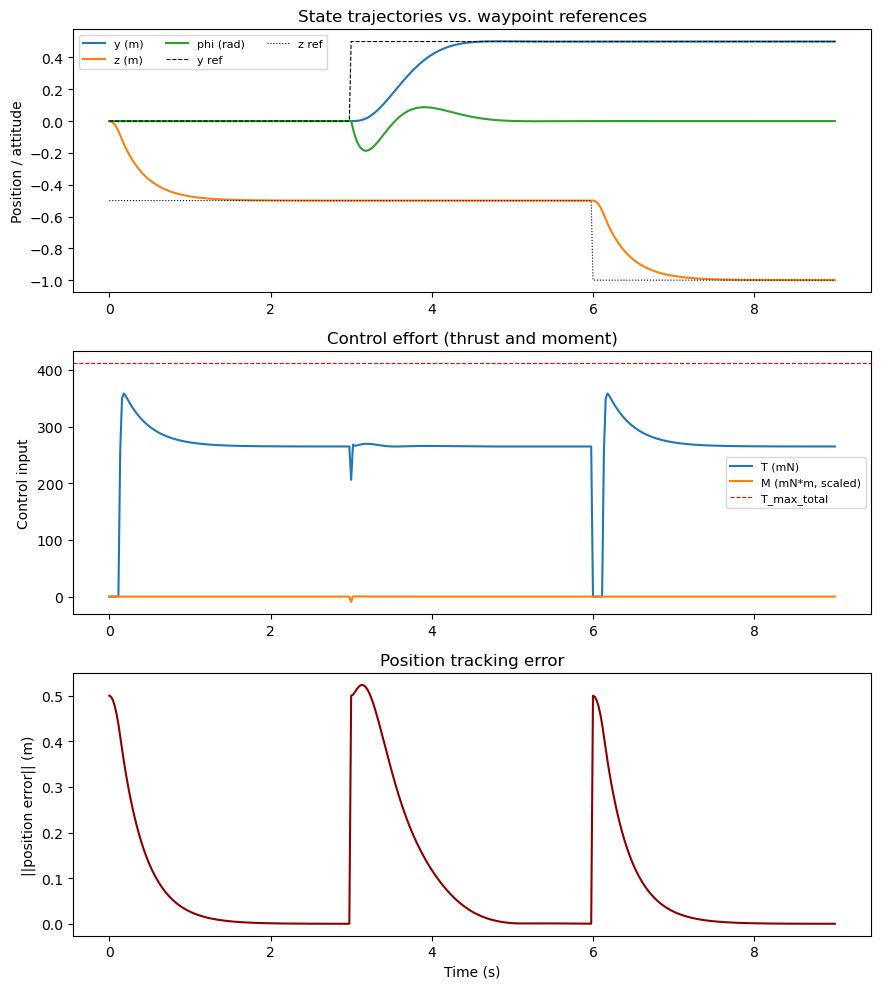

Saved: figures/states_control_error.png


In [ ]:
fig, axs = plt.subplots(3, 1, figsize=(9, 10))

# --- Plot 1: position / attitude vs time ---
axs[0].plot(sol.t, sol.y[0], label='y (m)')
axs[0].plot(sol.t, sol.y[1], label='z (m)')
axs[0].plot(sol.t, sol.y[2], label='phi (rad)')
ref_y = [reference(tt)[0] for tt in sol.t]
ref_z = [reference(tt)[1] for tt in sol.t]
axs[0].plot(sol.t, ref_y, 'k--', lw=0.8, label='y ref')
axs[0].plot(sol.t, ref_z, 'k:', lw=0.8, label='z ref')
axs[0].set_ylabel('Position / attitude')
axs[0].set_title('State trajectories vs. waypoint references')
axs[0].legend(ncol=3, fontsize=8)

# --- Plot 2: control inputs with saturation limits ---
axs[1].plot(sol.t, u_history[0]*1000, label='T (mN)')
axs[1].plot(sol.t, u_history[1]*1000, label='M (mN*m, scaled)')
axs[1].axhline(p.T_max_total*1000, color='r', ls='--', lw=0.8, label='T_max_total')
axs[1].set_ylabel('Control input')
axs[1].set_title('Control effort (thrust and moment)')
axs[1].legend(fontsize=8)

# --- Plot 3: tracking error norm ---
axs[2].plot(sol.t, error_history, color='darkred')
axs[2].set_ylabel('||position error|| (m)')
axs[2].set_xlabel('Time (s)')
axs[2].set_title('Position tracking error')

plt.tight_layout()
fig.savefig('figures/states_control_error.png', dpi=150)
plt.show()
print('Saved: figures/states_control_error.png')

### 5.4 Flight animation

In [ ]:
fig_anim, ax_anim = plt.subplots(figsize=(6, 6))
y_margin, z_margin = 0.3, 0.3
ax_anim.set_xlim(sol.y[0].min()-y_margin, sol.y[0].max()+y_margin)
ax_anim.set_ylim(sol.y[1].min()-z_margin, sol.y[1].max()+z_margin)
ax_anim.set_aspect('equal')
ax_anim.set_xlabel('y (m)')
ax_anim.set_ylabel('z (m)  [down = negative]')
ax_anim.set_title('Crazyflie 2.0 (2D reduction) -- waypoint flight')
ax_anim.invert_yaxis()  # so 'up' visually corresponds to negative z (climb)

trail_line, = ax_anim.plot([], [], 'b-', lw=1, alpha=0.4)
body_line, = ax_anim.plot([], [], 'ro-', lw=3, markersize=6)

n_frames = 150
frame_idx = np.linspace(0, len(sol.t)-1, n_frames).astype(int)

def animate(i):
    idx = frame_idx[i]
    trail_line.set_data(sol.y[0,:idx+1], sol.y[1,:idx+1])
    yc, zc, ph = sol.y[0,idx], sol.y[1,idx], sol.y[2,idx]
    dy = p.L * np.cos(ph)
    dz = p.L * np.sin(ph)
    body_line.set_data([yc-dy, yc+dy], [zc-dz, zc+dz])
    return trail_line, body_line

anim = animation.FuncAnimation(fig_anim, animate, frames=n_frames, interval=40, blit=True)

try:
    anim.save('outputs/flight.mp4', fps=25, dpi=150)
    print('Saved: outputs/flight.mp4')
except Exception as e:
    print('ffmpeg not available, falling back to GIF:', e)
    anim.save('outputs/flight.gif', writer=animation.PillowWriter(fps=25))
    print('Saved: outputs/flight.gif')

plt.close(fig_anim)

Saved: outputs/flight.mp4


---
## Summary

In [40]:
print('='*70)
print('PROJECT SUMMARY -- ME 4879 Course Project 2')
print('Vehicle: 2D-reduced Bitcraze Crazyflie 2.0 (real hardware)')
print('='*70)
print()
print('--- Segment 1: Vehicle parameters (real, cited) ---')
print(p)
print()
print('--- Segment 3: Open-loop stability ---')
print('Eigenvalues of A:', np.round(eigs_openloop, 4))
print(f'Controllability rank: {rank_ctrb}/{n_states} (full rank = controllable)')
print()
print('--- Segment 4: LQR design ---')
print('Q diagonal:', np.diag(Q))
print('R diagonal:', np.diag(R))
print('Closed-loop eigenvalues:', np.round(eigs_closedloop, 4))
print()
print('--- Segment 5: Simulation results ---')
print(f'Final tracking error: {error_history[-1]:.6f} m')
print(f'Max tracking error during flight: {error_history.max():.4f} m')
print()
print('Files generated in this run:')
for fn in ['outputs/bom.md', 'figures/perturbation_recovery.png',
           'figures/states_control_error.png', 'outputs/flight.mp4']:
    exists = os.path.exists(fn)
    print(f'  [{"OK" if exists else "MISSING"}] {fn}')

PROJECT SUMMARY -- ME 4879 Course Project 2
Vehicle: 2D-reduced Bitcraze Crazyflie 2.0 (real hardware)

--- Segment 1: Vehicle parameters (real, cited) ---
Crazyflie 2.0 (2D reduction)
  Mass m           = 27.0 g
  Arm length L     = 4.6 cm
  Pitch inertia I  = 1.400e-05 kg*m^2
  Hover thrust     = 264.9 mN
  Max total thrust = 412.0 mN
  Thrust/weight    = 1.56x

--- Segment 3: Open-loop stability ---
Eigenvalues of A: [0. 0. 0. 0. 0. 0.]
Controllability rank: 6/6 (full rank = controllable)

--- Segment 4: LQR design ---
Q diagonal: [50 50 20  5  5  2]
R diagonal: [1.e+00 5.e+03]
Closed-loop eigenvalues: [-1428.5679+0.j        -2.7849+2.7849j    -2.7849-2.7849j
    -3.1623+0.j       -82.7568+0.j        -3.1646+0.j    ]

--- Segment 5: Simulation results ---
Final tracking error: 0.000048 m
Max tracking error during flight: 0.5237 m

Files generated in this run:
  [MISSING] outputs/bom.md
  [OK] figures/perturbation_recovery.png
  [OK] figures/states_control_error.png
  [OK] outputs/fl

## References

1. Förster, J., Hamer, M., D'Andrea, R. *System Identification of the Crazyflie 2.0 Nano Quadrocopter.* Bachelor Thesis, ETH Zürich, 2015.
2. Rubí, B., Pérez, R., Morcego, B. *A Survey of Path Following Control Strategies for UAVs Focused on Quadrotors.* Journal of Intelligent & Robotic Systems, 2020. (arXiv:1608.05786 — reproduces Förster's Table 2.3.1 of identified Crazyflie 2.0 parameters)
3. Bitcraze AB. *Crazyflie 2.0 Product Page and Datasheet.* https://store.bitcraze.io/products/crazyflie-2-0
4. Giernacki, W. et al. *Crazyflie 2.0 Quadrotor as a Platform for Research and Education.* https://www.bitcraze.io/papers/giernacki_draft_crazyflie2.0.pdf
5. Bitcraze AB. *Demystifying Drone Dynamics.* https://www.bitcraze.io/2018/11/demystifying-drone-dynamics/